# Level 1: Matrix-multiplication memory-access analysis

**Starting point:** no downloaded model, dataset, or GPU is needed. We create small deterministic matrices and record **modelled algorithm-level accesses** while computing `C = A × B`.

**Important:** these are not captured CPU/GPU instructions or DRAM transactions, and not evidence about an entire LLM. Interpreter accesses, compiler optimisations, register reuse, threading, and hardware timing are excluded. Official trace acceptance remains unconfirmed.

Use **Run All**. All cells are reproducible; changing dimensions below regenerates traces and reports.

In [ ]:
from pathlib import Path
import sys, csv, json
from collections import Counter
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

# Works from repository root, Phase1/, or level1/; no machine-local path.
HERE = Path.cwd().resolve()
LEVEL1_DIR = next((candidate for parent in (HERE, *HERE.parents)
                   for candidate in (parent / 'level1', parent / 'Phase1' / 'level1')
                   if (candidate / 'generate_matmul_trace.py').is_file()), None)
if LEVEL1_DIR is None:
    raise RuntimeError('Launch Jupyter from the repository, Phase1, or Phase1/level1 directory.')
ROOT = LEVEL1_DIR.parent
sys.path.insert(0, str(LEVEL1_DIR))
from generate_matmul_trace import Config, generate
from analyze_trace import analyze, markdown_report

CONFIG = Config(m=16, k=16, n=32)
LINE_SIZE = 64  # analysis assumption, not an organiser requirement
OUT = ROOT / 'level1' / 'results' / 'modelled_matmul'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})
print('Phase root:', ROOT.name)
print('A: M×K; B: K×N; C: M×N; configuration:', CONFIG)

## 1. What are we recording?

All arrays use row-major storage, four-byte integer elements and separate aligned model address regions.

`address(A[i,k]) = base_A + (i*K + k)*4`  
`address(B[k,j]) = base_B + (k*N + j)*4`  
`address(C[i,j]) = base_C + (i*N + j)*4`

Both variants initialise C with writes, then perform the same multiply-accumulates in different orders:

- `ijk`: i outermost, j next, k innermost.
- `ikj`: i outermost, k next, j innermost.

**Explicit access policy:** each multiply-accumulate logs A-read, B-read, C-read, C-write. We intentionally do not hoist A or retain C in registers. This keeps the operation counts equal; it is a modelling choice, not a claim about optimised machine code. Input construction is outside the trace. Sequence numbers are order, not cycles.

In [2]:
traces, metadata, outputs = {}, {}, {}
for order in ('ijk', 'ikj'):
    directory = OUT / order
    metadata[order] = generate(directory, CONFIG, order)
    with (directory / 'trace.csv').open() as source:
        traces[order] = list(csv.DictReader(source))
    outputs[order] = json.loads((directory / 'result.json').read_text())
    assert metadata[order]['reference_check_passed']
    assert len(traces[order]) == CONFIG.m * CONFIG.n + 4 * CONFIG.m * CONFIG.n * CONFIG.k
assert outputs['ijk'] == outputs['ikj']
print('Both loop orders match the numerical reference and each other.')
print('Accesses per trace:', len(traces['ijk']))
print('Address regions:', metadata['ijk']['regions'])
display(Markdown('First six records:\n\n```text\n' +
                 '\n'.join(str(row) for row in traces['ijk'][:6]) + '\n```'))

Both loop orders match the numerical reference and each other.
Accesses per trace: 33280
Address regions: {'A': {'base': 4096, 'size_bytes': 1024}, 'B': {'base': 8192, 'size_bytes': 2048}, 'C': {'base': 12288, 'size_bytes': 2048}}


First six records:

```text
{'sequence': '0', 'phase': 'initialise', 'operation': 'W', 'operand': 'C', 'address': '0x3000', 'size_bytes': '4', 'i': '0', 'j': '0', 'k': ''}
{'sequence': '1', 'phase': 'initialise', 'operation': 'W', 'operand': 'C', 'address': '0x3004', 'size_bytes': '4', 'i': '0', 'j': '1', 'k': ''}
{'sequence': '2', 'phase': 'initialise', 'operation': 'W', 'operand': 'C', 'address': '0x3008', 'size_bytes': '4', 'i': '0', 'j': '2', 'k': ''}
{'sequence': '3', 'phase': 'initialise', 'operation': 'W', 'operand': 'C', 'address': '0x300c', 'size_bytes': '4', 'i': '0', 'j': '3', 'k': ''}
{'sequence': '4', 'phase': 'initialise', 'operation': 'W', 'operand': 'C', 'address': '0x3010', 'size_bytes': '4', 'i': '0', 'j': '4', 'k': ''}
{'sequence': '5', 'phase': 'initialise', 'operation': 'W', 'operand': 'C', 'address': '0x3014', 'size_bytes': '4', 'i': '0', 'j': '5', 'k': ''}
```

## 2. Whole-trace summary

A cache sees the interleaved sequence, including the initialisation writes. Below, reads and writes are both counted as address observations. The analyser does not implement a write policy, cache, or latency model.

Footprint means distinct touched cache lines × line size. Reusing a line does **not** automatically mean a cache hit.

In [3]:
summaries = {}
for order, rows in traces.items():
    summary = analyze((int(row['address'], 16) for row in rows), line_size=LINE_SIZE)
    summaries[order] = summary
    directory = OUT / order
    (directory / 'summary.json').write_text(json.dumps(summary, indent=2) + '\n')
    (directory / 'report.md').write_text(markdown_report(summary))
header = '| Order | Accesses | Reads | Writes | Unique lines | Footprint (bytes) | Adjacent same-line % |\n|---|---:|---:|---:|---:|---:|---:|\n'
for order, rows in traces.items():
    s = summaries[order]
    operations = Counter(row['operation'] for row in rows)
    header += f"| {order} | {s['accesses']} | {operations['R']} | {operations['W']} | {s['unique_cache_lines']} | {s['touched_line_footprint_bytes']} | {100*s['adjacent_same_line_fraction']:.2f} |\n"
display(Markdown(header))

| Order | Accesses | Reads | Writes | Unique lines | Footprint (bytes) | Adjacent same-line % |
|---|---:|---:|---:|---:|---:|---:|
| ijk | 33280 | 24576 | 8704 | 80 | 5120 | 26.06 |
| ikj | 33280 | 24576 | 8704 | 80 | 5120 | 26.06 |


## 3. Look inside each operand stream

The combined stream jumps between A, B and C. That can hide simple patterns. We therefore also inspect **compute-phase reads**, separately for each operand. This filtering helps diagnosis; the actual cache still receives the combined traffic.

Each graph shows up to 200 reads of that operand. The horizontal axis is the ordinal within the filtered operand stream, **not a timestamp**. The vertical axis is byte offset from that array's model base.

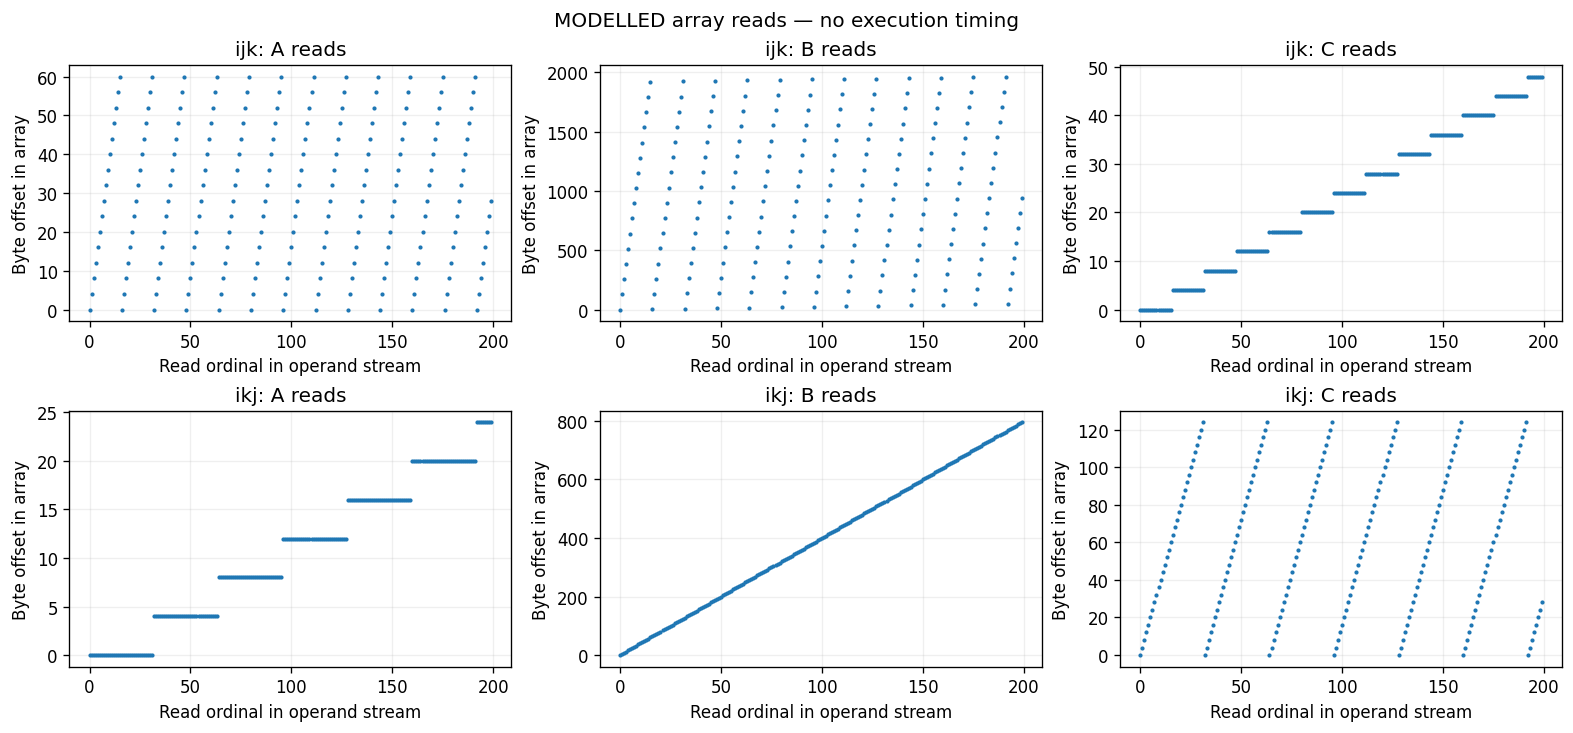

In [4]:
def compute_reads(order, operand):
    return [int(row['address'], 16) for row in traces[order]
            if row['phase'] == 'compute' and row['operation'] == 'R'
            and row['operand'] == operand]

fig, axes = plt.subplots(2, 3, figsize=(13, 6), constrained_layout=True)
for row_index, order in enumerate(('ijk', 'ikj')):
    for column, operand in enumerate(('A', 'B', 'C')):
        addresses = compute_reads(order, operand)[:200]
        base = metadata[order]['regions'][operand]['base']
        ax = axes[row_index, column]
        ax.plot(range(len(addresses)), [address-base for address in addresses], '.', markersize=3)
        ax.set(title=f'{order}: {operand} reads', xlabel='Read ordinal in operand stream', ylabel='Byte offset in array')
fig.suptitle('MODELLED array reads — no execution timing')
fig.savefig(OUT / 'operand_access_patterns.png')
plt.show()

## 4. Why loop order changes B accesses

With `ijk`, k changes fastest. Consecutive inner-loop B reads advance by `N*4` bytes. With `ikj`, j changes fastest and B advances by four bytes inside each row. Loop boundaries introduce other deltas.

A 64-byte line holds 16 four-byte elements. A four-byte step often stays within one cache line; a byte stride and a cache-line stride are different measurements. These histograms include loop-boundary transitions and show the eight most common values.

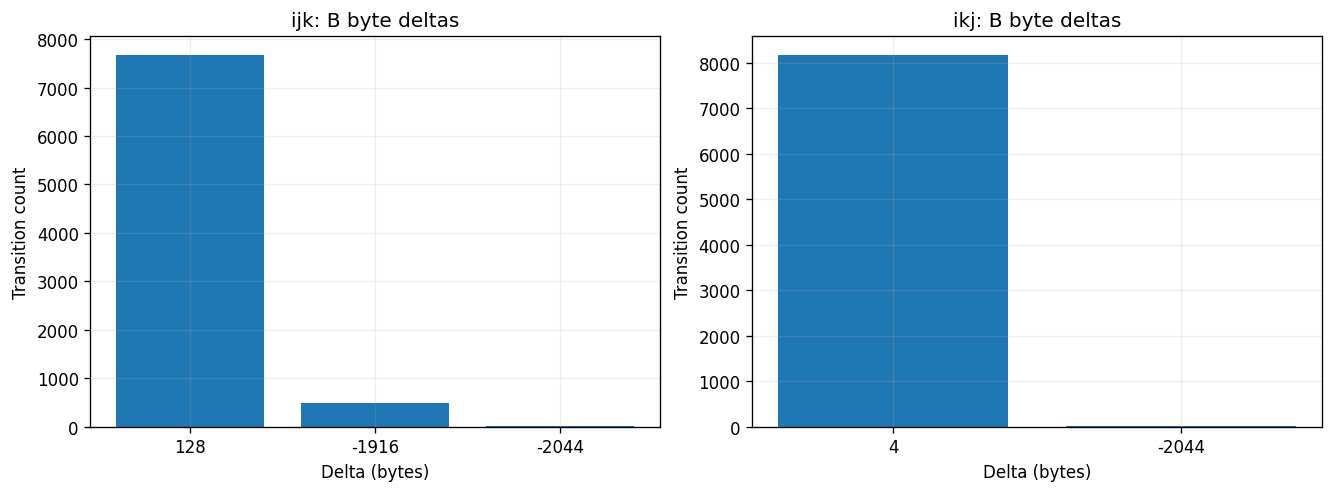

ijk B top byte deltas: [(128, 7680), (-1916, 496), (-2044, 15)]
ikj B top byte deltas: [(4, 8176), (-2044, 15)]


In [5]:
b_deltas = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, order in zip(axes, ('ijk', 'ikj')):
    addresses = compute_reads(order, 'B')
    counts = Counter(current-previous for previous, current in zip(addresses, addresses[1:]))
    b_deltas[order] = counts
    common = counts.most_common(8)
    ax.bar([str(delta) for delta, count in common], [count for delta, count in common])
    ax.set(title=f'{order}: B byte deltas', xlabel='Delta (bytes)', ylabel='Transition count')
fig.savefig(OUT / 'b_stride_comparison.png')
plt.show()
for order in ('ijk', 'ikj'):
    print(order, 'B top byte deltas:', b_deltas[order].most_common(4))

## 5. Reuse and line-size sensitivity

Reuse gap here is the access-index distance since a line's last observation. Gap 1 means immediate reuse. It is not stack/reuse distance and does not determine hit rate.

The line-size comparison changes how addresses are grouped. It does not simulate bigger/smaller caches or show which line size is fastest.

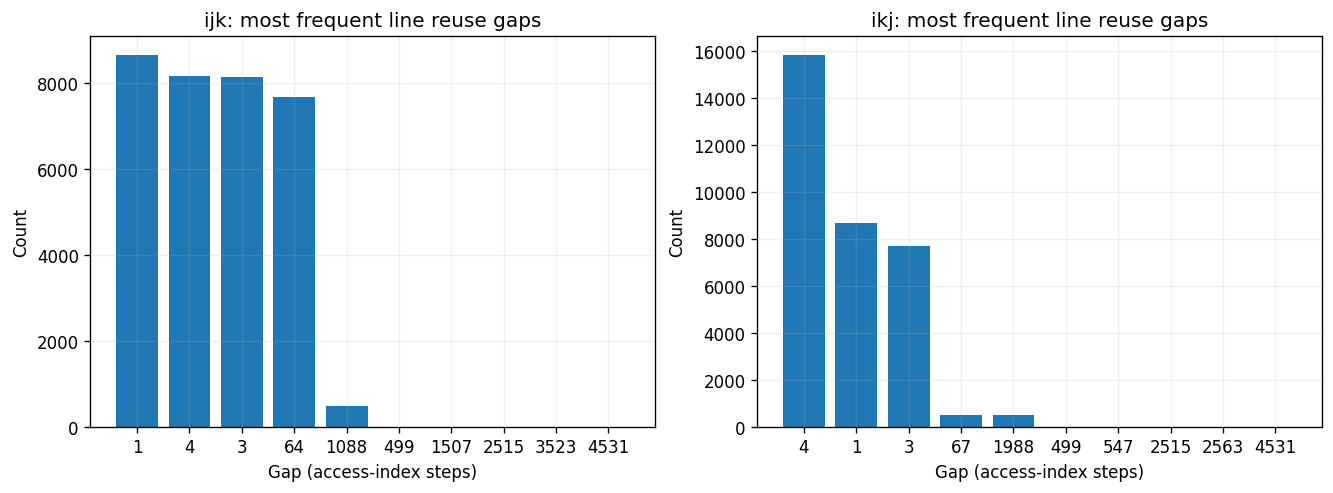

| Line bytes | Order | Unique lines | Touched-line footprint (bytes) |
|---:|---|---:|---:|
| 32 | ijk | 160 | 5120 |
| 32 | ikj | 160 | 5120 |
| 64 | ijk | 80 | 5120 |
| 64 | ikj | 80 | 5120 |
| 128 | ijk | 40 | 5120 |
| 128 | ikj | 40 | 5120 |


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, order in zip(axes, ('ijk', 'ikj')):
    common = summaries[order]['top_reuse_gaps']
    ax.bar([str(item['gap_accesses']) for item in common], [item['count'] for item in common])
    ax.set(title=f'{order}: most frequent line reuse gaps', xlabel='Gap (access-index steps)', ylabel='Count')
fig.savefig(OUT / 'reuse_gaps.png')
plt.show()
text = '| Line bytes | Order | Unique lines | Touched-line footprint (bytes) |\n|---:|---|---:|---:|\n'
for size in (32, 64, 128):
    for order, rows in traces.items():
        s = analyze((int(row['address'], 16) for row in rows), line_size=size)
        text += f"| {size} | {order} | {s['unique_cache_lines']} | {s['touched_line_footprint_bytes']} |\n"
display(Markdown(text))

## 6. Conclusions and next design questions

The cell below writes measured conclusions to disk. These are Level 1 observations, not a performance result. Next-line and stride prefetchers are candidates to test against a no-prefetch cache baseline. Per-operand clarity does not guarantee a global predictor can separate those streams.

No model weights or external dataset were downloaded. Before official submission, confirm whether modelled kernel traces are accepted or replace them with the supplied/captured workload trace.

In [7]:
report = f"""# Modelled matrix-multiplication analysis

## Provenance and assumptions
Generated locally by `generate_matmul_trace.py`. Algorithm-level addresses, not a captured CPU/GPU trace. Configuration: M={CONFIG.m}, K={CONFIG.k}, N={CONFIG.n}; row-major four-byte elements; analysis line size {LINE_SIZE} bytes. C initialisation is included. Every multiply-accumulate models A read, B read, C read and C write, without register reuse. No clocks or physical addresses are modelled.

## Measured observations
- Both orders passed an independent dot-product reference check and produced identical result matrices.
- Each trace contains {summaries['ijk']['accesses']:,} address observations.
- ijk touches {summaries['ijk']['unique_cache_lines']} lines; ikj touches {summaries['ikj']['unique_cache_lines']} lines. Equal footprint does not imply equal miss rate.
- B compute-read byte deltas (ijk, top four): {b_deltas['ijk'].most_common(4)}.
- B compute-read byte deltas (ikj, top four): {b_deltas['ikj'].most_common(4)}.
- The inner-loop B step is N*4 = {CONFIG.n*4} bytes for ijk and 4 bytes for ikj (where an inner loop has at least two iterations). Boundary transitions also occur.

## Design implications to investigate
Sequential/next-line fetching is a candidate for contiguous streams; a stride predictor is a candidate for regular non-unit streams. Interleaving can hide either pattern from a global predictor. C reuse and A repetition need cache evaluation, not an assumption of hits. Compare policies on the complete stream with explicitly defined write handling and identical resources.

## Limits and next steps
No hit rate, prefetch accuracy, bandwidth benefit, or speedup has been demonstrated. Add a baseline cache model next; hardware timing and actual workload validation follow later. Official acceptance of these modelled traces is unconfirmed. Figures and per-order raw traces, metadata, numeric outputs, and summaries are stored alongside this report.
"""
(OUT / 'analysis.md').write_text(report)
display(Markdown(report))
print('Saved outputs:', OUT.relative_to(ROOT))

# Modelled matrix-multiplication analysis

## Provenance and assumptions
Generated locally by `generate_matmul_trace.py`. Algorithm-level addresses, not a captured CPU/GPU trace. Configuration: M=16, K=16, N=32; row-major four-byte elements; analysis line size 64 bytes. C initialisation is included. Every multiply-accumulate models A read, B read, C read and C write, without register reuse. No clocks or physical addresses are modelled.

## Measured observations
- Both orders passed an independent dot-product reference check and produced identical result matrices.
- Each trace contains 33,280 address observations.
- ijk touches 80 lines; ikj touches 80 lines. Equal footprint does not imply equal miss rate.
- B compute-read byte deltas (ijk, top four): [(128, 7680), (-1916, 496), (-2044, 15)].
- B compute-read byte deltas (ikj, top four): [(4, 8176), (-2044, 15)].
- The inner-loop B step is N*4 = 128 bytes for ijk and 4 bytes for ikj (where an inner loop has at least two iterations). Boundary transitions also occur.

## Design implications to investigate
Sequential/next-line fetching is a candidate for contiguous streams; a stride predictor is a candidate for regular non-unit streams. Interleaving can hide either pattern from a global predictor. C reuse and A repetition need cache evaluation, not an assumption of hits. Compare policies on the complete stream with explicitly defined write handling and identical resources.

## Limits and next steps
No hit rate, prefetch accuracy, bandwidth benefit, or speedup has been demonstrated. Add a baseline cache model next; hardware timing and actual workload validation follow later. Official acceptance of these modelled traces is unconfirmed. Figures and per-order raw traces, metadata, numeric outputs, and summaries are stored alongside this report.
